In [1]:
# 1. 라이브러리 및 프로젝트 경로 설정
# %matplotlib widget: Jupyter 화면에서 마우스 클릭 좌표를 받을 수 있는 Matplotlib 백엔드
# 사용 전 apcms-ai 환경에 ipympl 및 ipykernel 설치 필요 (python -m pip install ipykernel)
%matplotlib widget

import json
import sys
import cv2
import matplotlib.pyplot as plt

from pathlib import Path

# 1-1. 현재 작업 폴더에서 프로젝트 루트(apcms_ai)를 찾기
# Notebook은 __file__을 제공하지 않으므로 Path.cwd()를 이용
# VS Code의 작업 폴더가 notebooks / ai_vision / apcms_ai / back일 수 있음
PROJECT_DIR = None
for folder in [Path.cwd(), *Path.cwd().parents]:
    candidates = [folder, folder / "apcms_ai"]
    for candidate in candidates:
        if (candidate / "ai_vision" / "paths.py").is_file():
            PROJECT_DIR = candidate
            break
    if PROJECT_DIR is not None:
        break

if PROJECT_DIR is None:
    raise FileNotFoundError("apcms_ai/ai_vision/paths.py를 찾지 못했습니다. Jupyter 작업 폴더를 확인하세요.")

# 1-2. ai_vision 패키지를 찾도록 상위 폴더(apcms_ai) 한 번만 등록
# 일반 .py에서는 python -m으로 실행하므로 이 설정이 필요하지 않음
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from ai_vision.paths import DATA_DIR, BASE_DIR

# 1-3. Windows 기본 한글 글꼴 적용
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

print("현재 작업 폴더:", Path.cwd())
print("프로젝트 루트:", PROJECT_DIR)
print("AI Vision 폴더:", BASE_DIR)

현재 작업 폴더: d:\finalProjectB\back\apcms_ai\ai_vision\notebooks
프로젝트 루트: d:\finalProjectB\back\apcms_ai
AI Vision 폴더: D:\finalProjectB\back\apcms_ai\ai_vision


In [2]:
# 2. 새로 촬영한 빈 주차면 기준 사진 읽기

# 2-1. 경로 설정: 기존 capture_empty_reference.py의 저장 경로와 같아야 함
IMAGE_PATH = DATA_DIR / "parking_spaces" / "empty_reference.jpg"
SAVE_PATH = DATA_DIR / "parking_spaces" / "parking_spots.json"

# 2-2. 이미지 읽기 및 파일 유효성 확인
if not IMAGE_PATH.is_file():
    raise FileNotFoundError(f"기준 이미지가 없습니다: {IMAGE_PATH}")

image_bgr = cv2.imread(str(IMAGE_PATH))
if image_bgr is None:
    raise ValueError(f"기준 이미지를 읽을 수 없습니다: {IMAGE_PATH}")

# OpenCV는 BGR, Matplotlib은 RGB를 사용하므로 색상 순서 변환
image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
height, width = image.shape[:2]

print("기준 이미지:", IMAGE_PATH)
print(f"해상도: {width} x {height}")
print("기준 이미지를 다시 촬영했다면 아래 셀에서 주차면 좌표도 다시 지정하세요.")

기준 이미지: D:\finalProjectB\back\apcms_ai\ai_vision\data\parking_spaces\empty_reference.jpg
해상도: 640 x 480
기준 이미지를 다시 촬영했다면 아래 셀에서 주차면 좌표도 다시 지정하세요.


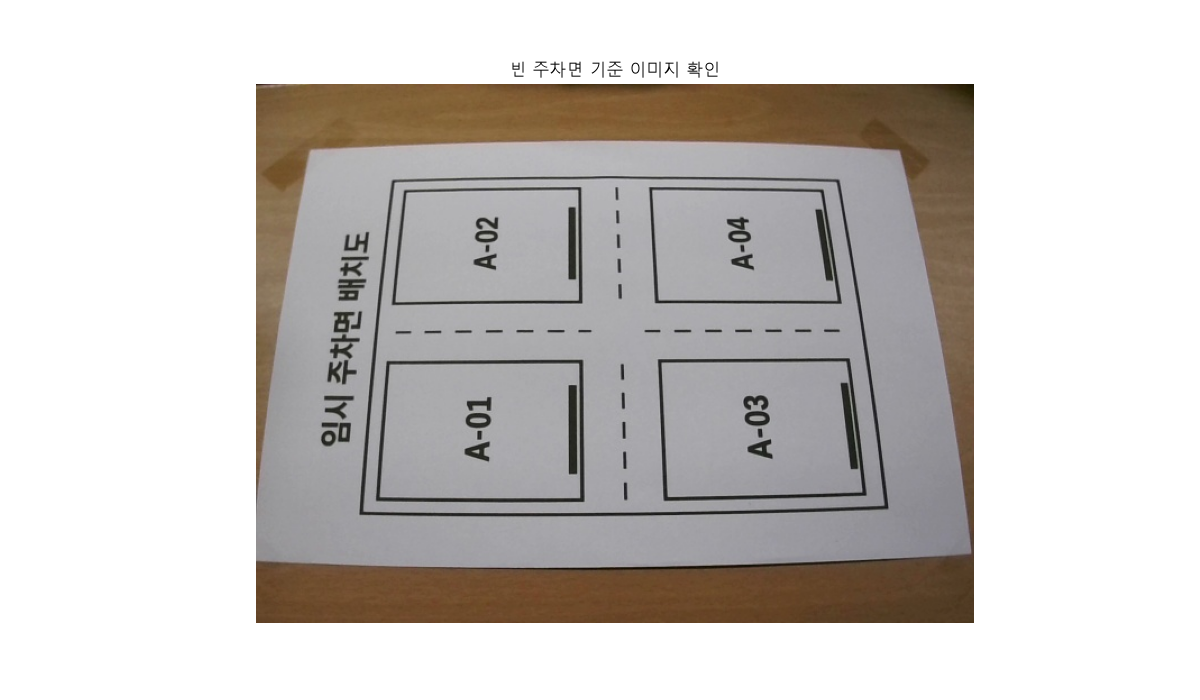

In [3]:
# 3. 기준 사진 미리보기

fig_preview, ax_preview = plt.subplots(figsize=(12, 7))
ax_preview.imshow(image)
ax_preview.set_title("빈 주차면 기준 이미지 확인")
ax_preview.axis("off")
plt.show()

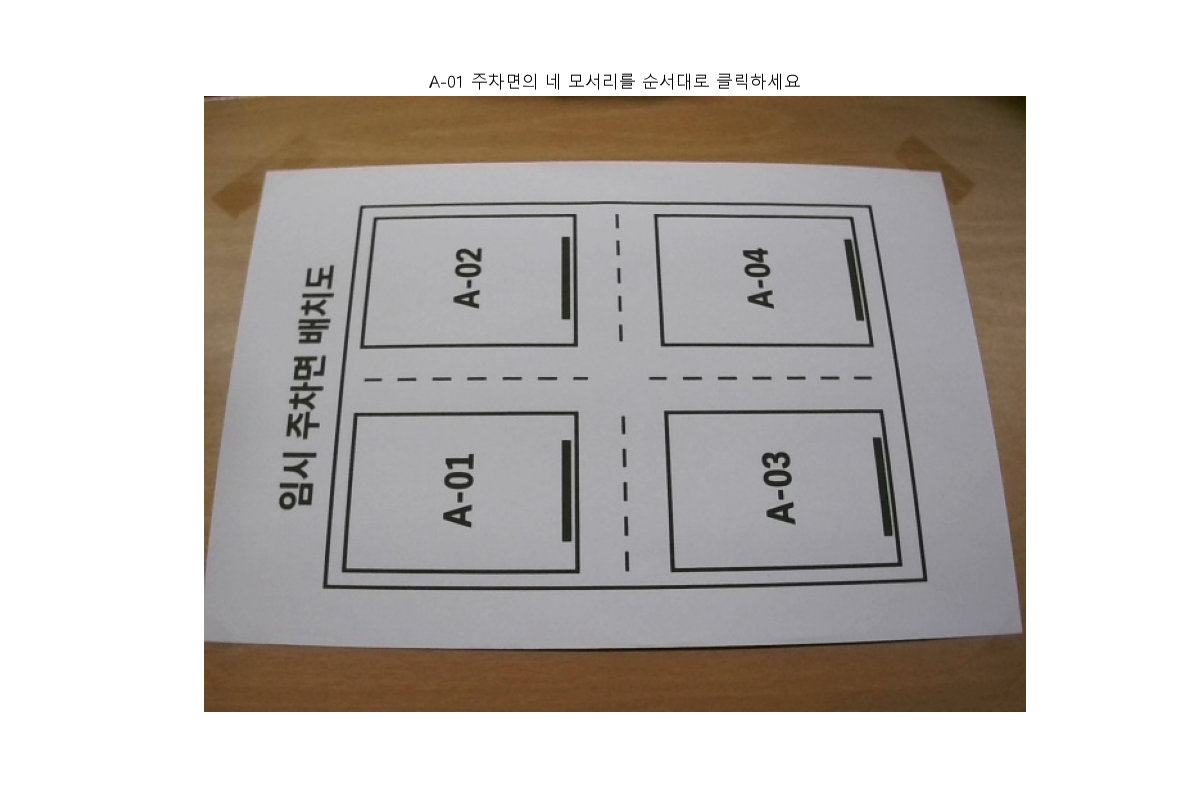

In [4]:
# 4. 마우스 클릭으로 주차면 4개 좌표 지정
# 주차면 하나당 꼭짓점 4개를 시계방향 또는 반시계방향 순서로 클릭
# A-01 -> A-02 -> A-03 -> A-04 순서로 자동 등록
# 잘못 클릭했다면 이 셀을 다시 실행하여 좌표를 처음부터 지정

# 4-1. 이전 클릭 그림이 남아 있으면 닫아서 중복 이벤트 연결 방지
# globals(): 현재 실행 환경에 정의된 변수 목록을 확인
# 이전 셀 실행에서 fig_annotation이 생성되었는지 검사
if "fig_annotation" in globals():
    plt.close(globals()["fig_annotation"])

SPACE_NAMES = ["A-01", "A-02", "A-03", "A-04"]
spaces = []             # 완성된 주차면 목록
points = []             # 현재 주차면을 위해 클릭 중인 좌표 4개

fig_annotation, ax_annotation = plt.subplots(figsize=(12, 8))
ax_annotation.imshow(image)
ax_annotation.set_title(f"{SPACE_NAMES[0]} 주차면의 네 모서리를 순서대로 클릭하세요")
ax_annotation.axis("off")

# 4-2. 마우스를 클릭할 때 호출되는 함수
def onclick(event):
    # 이미지 축 밖을 클릭하거나 왼쪽 버튼이 아니면 무시
    if event.inaxes != ax_annotation or event.button != 1:
        return

    # 4개 주차면이 모두 완성됐다면 추가 클릭 무시
    if len(spaces) >= len(SPACE_NAMES):
        return

    # 유효한 이미지 좌표인지 검사
    if event.xdata is None or event.ydata is None:
        return

    x = int(event.xdata)
    y = int(event.ydata)
    if not (0 <= x < width and 0 <= y < height):
        return

    # 4-3. 클릭한 점을 저장하고 빨간 원으로 표시
    points.append([x, y])
    ax_annotation.plot(x, y, "ro", markersize=5)

    # 4-4. 현재 주차면의 네 모서리가 채워진 경우
    if len(points) == 4:
        name = SPACE_NAMES[len(spaces)]
        selected = points.copy()   # clear() 전에 복사하여 저장
        spaces.append({"id": name, "points": selected})

        # 마지막 점에서 첫 점으로 이어지는 폐곡선 표시
        polygon = selected + [selected[0]]
        xs = [p[0] for p in polygon]
        ys = [p[1] for p in polygon]
        ax_annotation.plot(xs, ys, color="lime", linewidth=2)
        print(f"[좌표 지정] {name}: {selected}")

        points.clear()

        if len(spaces) < len(SPACE_NAMES):
            ax_annotation.set_title(
                f"{SPACE_NAMES[len(spaces)]} 주차면의 네 모서리를 순서대로 클릭하세요"
            )
        else:
            ax_annotation.set_title("주차면 4개 지정 완료! 아래 저장 셀을 실행하세요")
            # 더 이상 클릭 이벤트를 받을 필요가 없어 연결 해제
            fig_annotation.canvas.mpl_disconnect(click_connection_id)

    # 클릭된 점과 선을 화면에 즉시 반영
    fig_annotation.canvas.draw_idle()

# 4-5. 클릭 이벤트 연결. 반환값은 나중에 연결 해제할 때 사용
click_connection_id = fig_annotation.canvas.mpl_connect("button_press_event", onclick)
plt.show()

In [5]:
# 5. 현재 지정된 주차면 좌표 확인 (저장 전)

print(f"완료한 주차면: {len(spaces)} / {len(SPACE_NAMES)}개")
for space in spaces:
    print(space["id"], ":", space["points"])

if len(spaces) != len(SPACE_NAMES) or points:
    print("[안내] 아직 좌표 지정이 끝나지 않았습니다. 4개 주차면을 모두 선택하세요.")
else:
    print("[확인] 4개 주차면 좌표 지정 완료. 다음 저장 셀을 실행하세요.")

완료한 주차면: 4 / 4개
A-01 : [[117, 245], [109, 368], [289, 368], [289, 246]]
A-02 : [[132, 95], [120, 195], [289, 192], [287, 93]]
A-03 : [[359, 246], [364, 370], [541, 364], [526, 247]]
A-04 : [[350, 92], [356, 193], [520, 193], [504, 95]]
[확인] 4개 주차면 좌표 지정 완료. 다음 저장 셀을 실행하세요.


In [6]:
# 6. JSON 저장 (4개 주차면 모두 지정됐을 때만)

# 6-1. 실수로 spaces: []를 저장하여 기존 좌표를 덮어쓰지 않도록 방지
if len(spaces) != len(SPACE_NAMES) or points:
    raise ValueError(
        f"좌표 지정이 완료되지 않았습니다: {len(spaces)}/{len(SPACE_NAMES)}개. "
        "4번 셀에서 모든 주차면의 네 모서리를 클릭한 뒤 다시 실행하세요."
    )

# 6-2. 기존 parking_realtime.py가 읽는 구조 그대로 유지
output = {
    "image_width": width,
    "image_height": height,
    "spaces": spaces
}

# 6-3. JSON 저장 폴더 생성 및 파일 쓰기
SAVE_PATH.parent.mkdir(parents=True, exist_ok=True)
with open(SAVE_PATH, "w", encoding="utf-8") as file:
    json.dump(output, file, ensure_ascii=False, indent=4)

print("[저장 완료] 주차면 좌표 JSON:", SAVE_PATH)
print(f"저장된 주차면 수: {len(spaces)}개")

[저장 완료] 주차면 좌표 JSON: D:\finalProjectB\back\apcms_ai\ai_vision\data\parking_spaces\parking_spots.json
저장된 주차면 수: 4개


In [7]:
# 7. 저장된 JSON 다시 읽어서 검증

with open(SAVE_PATH, "r", encoding="utf-8") as file:
    saved_data = json.load(file)

assert saved_data["image_width"] == width, "이미지 가로 크기가 다릅니다."
assert saved_data["image_height"] == height, "이미지 세로 크기가 다릅니다."
assert len(saved_data["spaces"]) == len(SPACE_NAMES), "저장된 주차면 개수가 다릅니다."
assert [s["id"] for s in saved_data["spaces"]] == SPACE_NAMES, "주차면 ID 순서가 다릅니다."

print("[검증 성공] 이미지 해상도 및 4개 주차면 정보가 정상 저장되었습니다.")
for space in saved_data["spaces"]:
    print(space["id"], space["points"])

[검증 성공] 이미지 해상도 및 4개 주차면 정보가 정상 저장되었습니다.
A-01 [[117, 245], [109, 368], [289, 368], [289, 246]]
A-02 [[132, 95], [120, 195], [289, 192], [287, 93]]
A-03 [[359, 246], [364, 370], [541, 364], [526, 247]]
A-04 [[350, 92], [356, 193], [520, 193], [504, 95]]
